# Delivery & Operations

## Business Case

### PERTANYAAN BUSINESS

1. Berapa rata-rata waktu pengiriman aktual vs estimasi per state?
2. Berapa persentase order yang terlambat dari estimasi pengiriman?
3. State mana yang memiliki rata-rata keterlambatan pengiriman tertinggi?

### SCOPE ANALYSIS

Analisis menggunakan order dengan ``order_status`` = **'delivered'** karena fokus analisis adalah waktu dan ketepatan pengiriman aktual kepada customer.

## IMPORT LIBRARY

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

## GATHERING DATA

In [2]:
order = pd.read_csv('https://raw.githubusercontent.com/adinfir/data-new/refs/heads/main/E-commerce-public-dataset/orders_dataset.csv')
customer = pd.read_csv('https://raw.githubusercontent.com/adinfir/data-new/refs/heads/main/E-commerce-public-dataset/customers_dataset.csv')

## DATA UNDERSTANDING

In [3]:
order.head(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
customer.head(5)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


### GRAIN

1. tabel order : 1 row merepresntasikan 1 order
2. tabel customer : 1 row mempresentasikan 1 pelanggan atau customer

### KEY COLUMNS

1. **Tabel `orders`**:
   - `order_id` → identifier untuk setiap order
   - `customer_id` → identifier customer digunakan untuk menghubungkan `order` dengan `customer`
   - `order_status` → status order
   - `order_delivered_customer_date` → waktu saat pelanggan menerima barang
   - `order_estimated_delivery_date` → estimasi waktu saat pelanggan menerima barang

2. **Tabel `Customer`**
   - `customer_id` → identifier untuk setiap customer
   - `customer_unique_id` → ID yang merepresentasikan customer yang sebenarnya/unik
   - `customer_state` → customer state

### RELATIONSHIP TABLE


- Tabel `orders` dan `order_items` terhubung melalui `order_id`.
- Tabel `order_items` dan `seller` terhubung melalui `seller_id`.

- `order` memiliki hubungan **one-to-many (1:N)** dengan `order_items`, karena satu order dapat memiliki beberapa item.
- `seller` memiliki hubungan **one-to-many (1:N)** dengan `order_items`, karena satu seller dapat terkait dengan beberapa order_items.

## DATA QUALITY

### ASESSING DATA

In [5]:
order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


 Kolom `order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, dan `order_estimated_delivery_date` masih memiliki tipe data **object**, sehingga perlu dikonversi ke tipe **datetime** sebelum digunakan dalam analisis berbasis waktu


In [6]:
order.describe(include='all')

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-04-11 10:48:14,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-08 23:38:46,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [7]:
print('Checking null value')
order.isna().sum()

Checking null value


order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Pada kolom `order_approved_at`, `order_delivered_carrier_date`, dan `order_delivered_customer_date` terdapat **missing value** yang perlu ditangani sebelum dilakukan analisis lebih lanjut.


In [8]:
print('Checking duplicated value')
order.duplicated().sum()

Checking duplicated value


0

In [9]:
customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [10]:
customer.describe(include='all')

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
count,99441,99441,99441.000000,99441,99441
unique,99441,96096,NaN,4119,27
top,06b8999e2fba1a1fbc88172c00ba8bc7,8d50f5eadf50201ccdcedfb9e2ac8455,NaN,sao paulo,SP
freq,1,17,NaN,15540,41746
mean,NaN,NaN,35137.474583,NaN,NaN
std,NaN,NaN,29797.938996,NaN,NaN
min,NaN,NaN,1003.000000,NaN,NaN
25%,NaN,NaN,11347.000000,NaN,NaN
50%,NaN,NaN,24416.000000,NaN,NaN
75%,NaN,NaN,58900.000000,NaN,NaN


In [11]:
print('Checking null value')
customer.isna().sum()

Checking null value


customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [12]:
print('Checking duplicated value')
customer.duplicated().sum()

Checking duplicated value


0

### CLEANING DATA

## PREPARATION DATA

### MENGUBAH TIPE DATA PADA TABEL ORDER

Mengubah kolom `order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, dan `order_estimated_delivery_date` dari tipe data **object** menjadi **datetime** agar dapat digunakan dalam analisis berbasis waktu.


In [13]:
order['order_purchase_timestamp'] = pd.to_datetime(order['order_purchase_timestamp'])
order['order_approved_at'] = pd.to_datetime(order['order_approved_at'])
order['order_delivered_carrier_date'] = pd.to_datetime(order['order_delivered_carrier_date'])
order['order_delivered_customer_date'] = pd.to_datetime(order['order_delivered_customer_date'])
order['order_estimated_delivery_date'] = pd.to_datetime(order['order_estimated_delivery_date'])

### MELAKUKAN FILTER TABEL ORDER DENGAN ORDER_STATUS = DELIVERED

**Catatan:** Analisis difokuskan pada order dengan `order_status = 'delivered'` untuk memastikan transaksi yang dianalisis merupakan order yang telah berhasil diselesaikan.


In [14]:
order = order[order['order_status'] == 'delivered']
order.isna().sum()

order_id                          0
customer_id                       0
order_status                      0
order_purchase_timestamp          0
order_approved_at                14
order_delivered_carrier_date      2
order_delivered_customer_date     8
order_estimated_delivery_date     0
dtype: int64

#### Data Quality Note

Setelah memfilter order dengan status **`delivered`**, ditemukan missing value pada beberapa kolom terkait proses pengiriman.

Untuk analisis Delivery & Operations, kolom yang digunakan adalah `order_purchase_timestamp`, `order_delivered_customer_date`, dan `order_estimated_delivery_date`. Dari ketiga kolom tersebut, hanya `order_delivered_customer_date` yang memiliki missing value sebanyak **8 order**.

Karena `order_delivered_customer_date` digunakan untuk menghitung waktu pengiriman aktual, nilai yang hilang tidak dapat diimputasi dan order tersebut dikeluarkan dari analisis Q1–Q3.


### MELAKUKAN PENGELUARAN DATA YANG kolom `order_delivered_customer_date` memiliki nilai null

In [15]:
order = order[order['order_delivered_customer_date'].notnull()]

In [16]:
order.isna().sum()

order_id                          0
customer_id                       0
order_status                      0
order_purchase_timestamp          0
order_approved_at                14
order_delivered_carrier_date      1
order_delivered_customer_date     0
order_estimated_delivery_date     0
dtype: int64

### JOIN TABLE

In [17]:
# Join tabel order dan customer
order_customer = pd.merge(
    left = order,
    right = customer,
    how = 'left',
    on = 'customer_id'
)
order_customer.isna().sum()

order_id                          0
customer_id                       0
order_status                      0
order_purchase_timestamp          0
order_approved_at                14
order_delivered_carrier_date      1
order_delivered_customer_date     0
order_estimated_delivery_date     0
customer_unique_id                0
customer_zip_code_prefix          0
customer_city                     0
customer_state                    0
dtype: int64

## EXPLORATORY DATA ANALYSIS

### 1.  Berapa rata-rata waktu pengiriman aktual vs estimasi per state?

In [18]:
data_q1 = order_customer[['customer_state', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']]

In [19]:
# Menghitung actual delivery days dari tanggal pengiriman aktual dikurangi tanggal pemesanan
data_q1['actual_days'] = ((data_q1['order_delivered_customer_date'] - data_q1['order_purchase_timestamp']).dt.total_seconds() / 86400)

C:\Users\adien\AppData\Local\Temp\ipykernel_19048\744646654.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_q1['actual_days'] = ((data_q1['order_delivered_customer_date'] - data_q1['order_purchase_timestamp']).dt.total_seconds() / 86400)


In [20]:
# Menghitung estimation delivery days dari estimasi pengiriman dikurangi tanggal pemesanan
data_q1['estimation_days'] = ((data_q1['order_estimated_delivery_date'] - data_q1['order_purchase_timestamp']).dt.total_seconds() / 86400)

C:\Users\adien\AppData\Local\Temp\ipykernel_19048\1948779428.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_q1['estimation_days'] = ((data_q1['order_estimated_delivery_date'] - data_q1['order_purchase_timestamp']).dt.total_seconds() / 86400)


In [21]:
data_q1

,customer_state,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,actual_days,estimation_days
0,SP,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,8.436574,15.544063
1,BA,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,13.782037,19.137766
2,GO,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,9.394213,26.639711
3,RN,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,13.208750,26.188819
4,SP,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,2.873877,12.112049
...,...,...,...,...,...,...
96465,SP,2017-03-09 09:54:05,2017-03-17 15:08:01,2017-03-28,8.218009,18.587442
96466,SP,2018-02-06 12:58:58,2018-02-28 17:37:56,2018-03-02,22.193727,23.459051
96467,BA,2017-08-27 14:46:43,2017-09-21 11:24:17,2017-09-27,24.859421,30.384225
96468,RJ,2018-01-08 21:28:27,2018-01-25 23:32:54,2018-02-15,17.086424,37.105243


In [22]:
# Agregasi rata-rata actual delivery dan estimasi delivery tiap state 
data_q1_clean = data_q1.groupby('customer_state').agg({
    'actual_days' : 'mean',
    'estimation_days' : 'mean'
})
data_q1_clean

,actual_days,estimation_days
customer_state,,
AC,21.035713,41.112720
AL,24.543855,32.575914
AM,26.425991,45.277808
AP,27.185068,46.244490
BA,19.335466,29.434538
CE,21.266579,31.376585
DF,12.967568,24.307093
ES,15.789307,25.586416
GO,15.606339,27.089915


In [23]:
# # Menghitung selisih antara estimasi dan durasi pengiriman aktual
data_q1_clean['avg_diff_days'] = (
    data_q1_clean['estimation_days'] -
    data_q1_clean['actual_days'] )

In [24]:
data_q1_clean.sort_values(by='avg_diff_days', ascending=False)

,actual_days,estimation_days,avg_diff_days
customer_state,,,
AC,21.035713,41.112720,20.077007
RO,19.372037,38.768863,19.396826
AP,27.185068,46.244490,19.059423
AM,26.425991,45.277808,18.851817
RR,29.387546,45.982144,16.594598
MT,18.055756,31.741306,13.685550
PA,23.772917,37.159205,13.386288
RS,15.300276,28.508765,13.208489
RN,19.278156,32.240505,12.962349


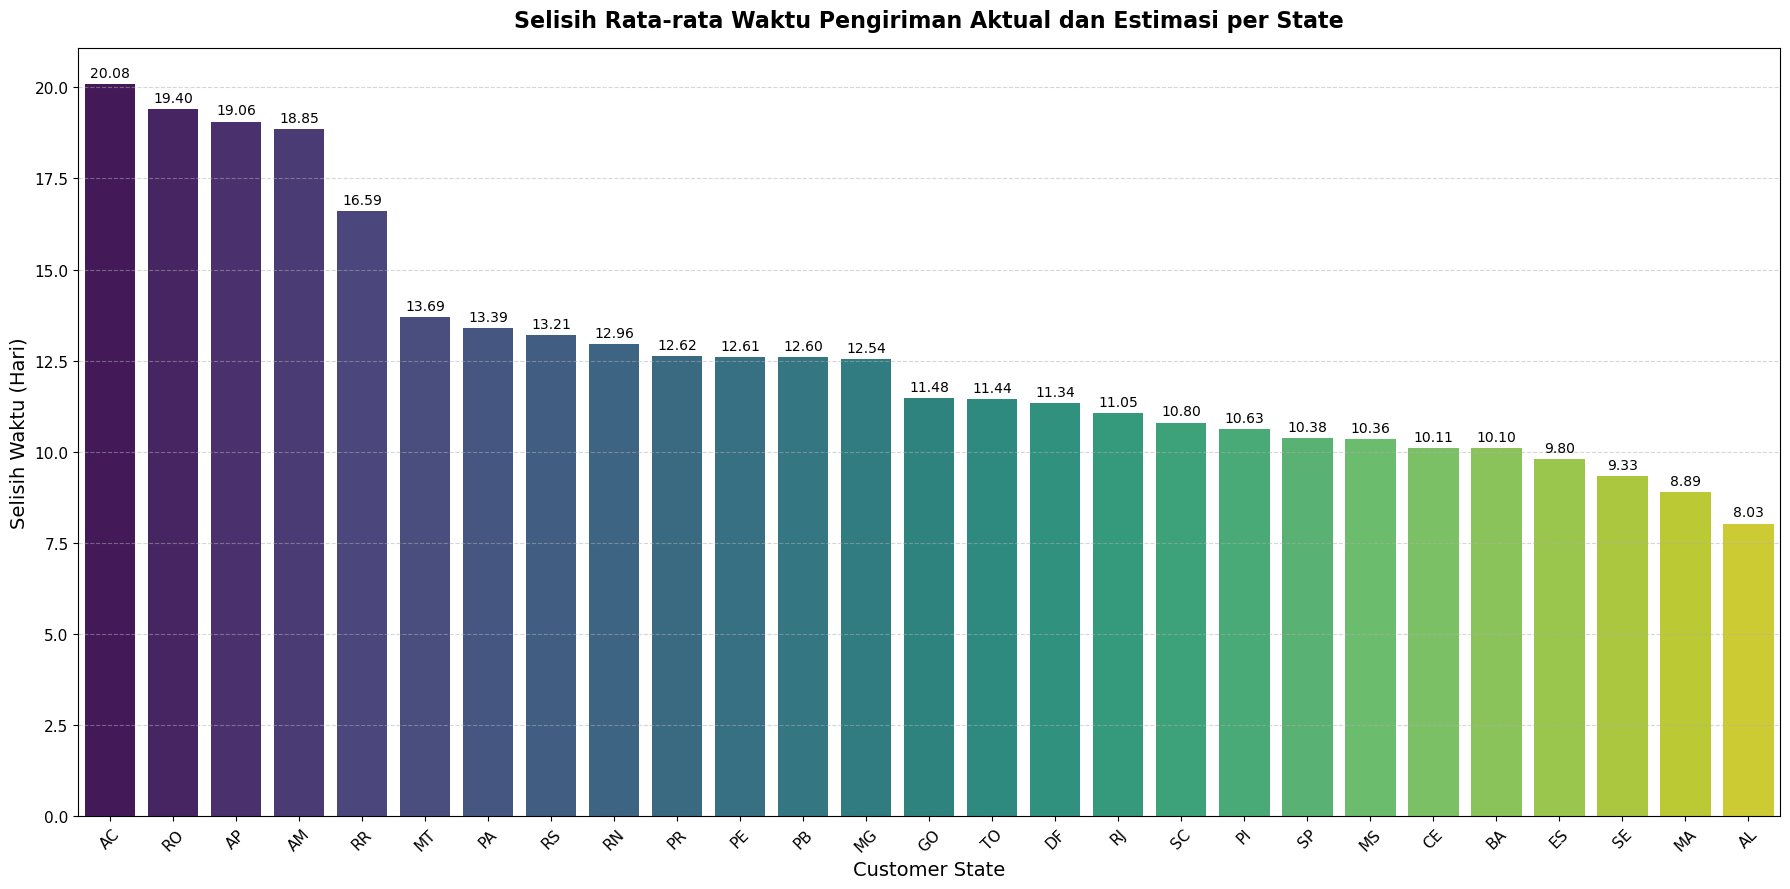

In [25]:
# Mengurutkan state berdasarkan selisih rata-rata estimasi dan durasi pengiriman aktual
avg_state_desc = data_q1_clean.sort_values(by='avg_diff_days',ascending=False)

# Membuat vertical bar chart
plt.figure(figsize=(18, 9))

ax = sns.barplot(
    data=avg_state_desc,
    x='customer_state',
    y='avg_diff_days',
    hue='customer_state',
    palette='viridis',
    legend=False
)

# Menambahkan label selisih hari pada setiap batang
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='{:,.2f}',
        padding=3,
        fontsize=10
    )

# Menambahkan judul dan label sumbu
plt.title(
    'Selisih Rata-rata Waktu Pengiriman Aktual dan Estimasi per State',
    fontsize=16,
    fontweight='bold',
    pad=15
)
plt.xlabel('Customer State', fontsize=14)
plt.ylabel('Selisih Waktu (Hari)', fontsize=14)

# Memutar label state agar lebih mudah dibaca
plt.xticks(rotation=45, fontsize=11)
plt.yticks(fontsize=11)

# Menambahkan grid horizontal untuk memudahkan perbandingan
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### KEY INSIGHT

Secara rata-rata, waktu pengiriman aktual di seluruh state lebih cepat dibandingkan estimasi yang diberikan kepada customer. Hal ini menunjukkan bahwa estimasi waktu pengiriman cenderung memberikan buffer waktu yang cukup, sehingga pengiriman aktual umumnya selesai sebelum tanggal estimasi.


### 2. Berapa persentase order yang terlambat dari estimasi pengiriman?

In [26]:
data_q2 = order_customer[['order_id', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']]

In [27]:
# Menghitung actual delivery days dari tanggal pengiriman aktual dikurangi tanggal pemesanan
data_q2['actual_days'] = ((data_q2['order_delivered_customer_date'] - data_q2['order_purchase_timestamp']).dt.total_seconds() / 86400)

C:\Users\adien\AppData\Local\Temp\ipykernel_19048\1522411137.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_q2['actual_days'] = ((data_q2['order_delivered_customer_date'] - data_q2['order_purchase_timestamp']).dt.total_seconds() / 86400)


In [28]:
# Menghitung estimation delivery days dari estimasi pengiriman dikurangi tanggal pemesanan
data_q2['estimation_days'] = ((data_q2['order_estimated_delivery_date'] - data_q2['order_purchase_timestamp']).dt.total_seconds() / 86400)

C:\Users\adien\AppData\Local\Temp\ipykernel_19048\2136300005.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_q2['estimation_days'] = ((data_q2['order_estimated_delivery_date'] - data_q2['order_purchase_timestamp']).dt.total_seconds() / 86400)


In [29]:
# Mengklasifikasikan order berdasarkan ketepatan waktu pengiriman
data_q2['status'] = np.where(data_q2['actual_days'] > data_q2['estimation_days'],'late','ontime')

C:\Users\adien\AppData\Local\Temp\ipykernel_19048\3174335629.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_q2['status'] = np.where(data_q2['actual_days'] > data_q2['estimation_days'],'late','ontime')


In [30]:
# Agregasi total order berdasarkan klasifikasi
data_q2_clean = data_q2.groupby(by='status')['order_id'].count().reset_index()
data_q2_clean

,status,order_id
0,late,7826
1,ontime,88644


In [31]:
# Menghitung persentase order berdasarkan total seluruh order
grand_total = data_q2_clean['order_id'].sum()
data_q2_clean['pct'] = (data_q2_clean['order_id'] / grand_total * 100).round(4)

In [32]:
# Mengganti nama kolom
data_q2_clean = data_q2_clean.rename(columns={
    'order_id': 'Total Order',
    }
)
data_q2_clean

,status,Total Order,pct
0,late,7826,8.1124
1,ontime,88644,91.8876


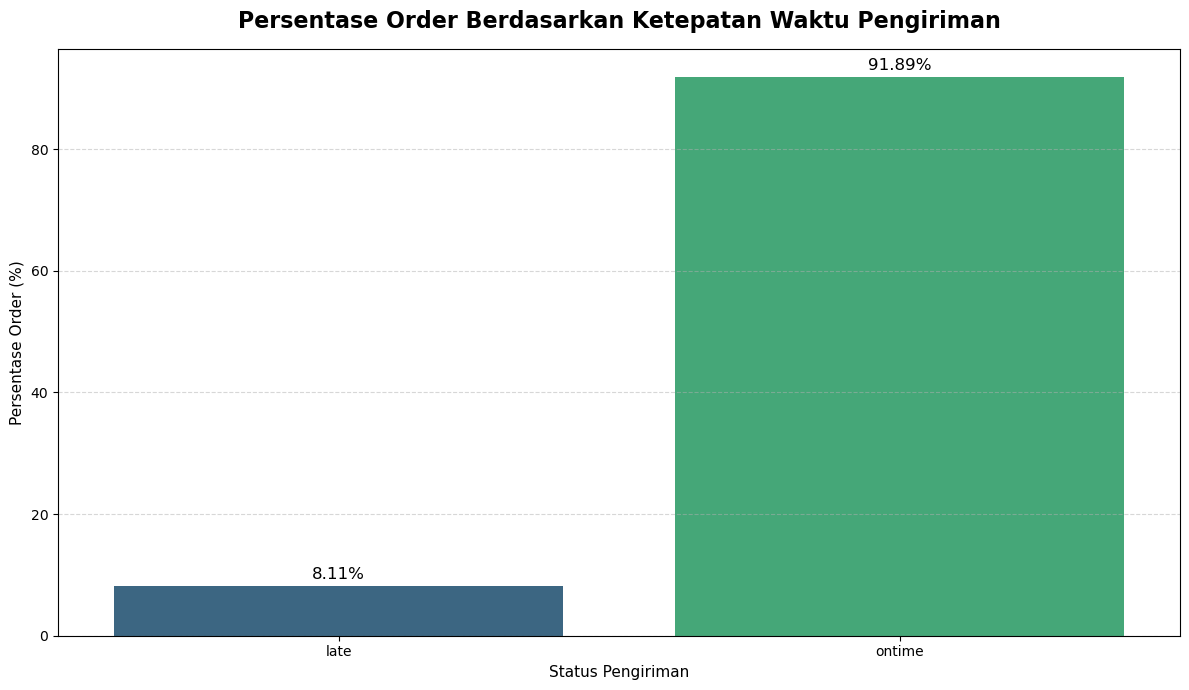

In [33]:
# Membuat vertical bar chart untuk membandingkan persentase order
# berdasarkan ketepatan waktu pengiriman
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=data_q2_clean,
    x='status',
    y='pct',
    hue='status',
    palette='viridis',
    legend=False
)

# Menambahkan label persentase pada setiap batang
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='{:,.2f}%',
        padding=3,
        fontsize=12
    )

# Menambahkan judul dan label sumbu
plt.title(
    'Persentase Order Berdasarkan Ketepatan Waktu Pengiriman',
    fontsize=16,
    fontweight='bold',
    pad=15
)
plt.xlabel('Status Pengiriman', fontsize=11)
plt.ylabel('Persentase Order (%)', fontsize=11)

# Menambahkan grid horizontal untuk memudahkan perbandingan
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### KEY INSIGHT

Mayoritas order, yaitu **91,8876% (88.644 order)**, berhasil dikirim **tepat waktu sesuai estimasi**, sedangkan **8,1124% (7.826 order)** mengalami keterlambatan

### 3. State mana yang memiliki rata-rata keterlambatan pengiriman tertinggi?

In [34]:
data_q3 = order_customer[['customer_state','order_id', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']]

In [35]:
# Menghitung actual delivery days dari tanggal pengiriman aktual dikurangi tanggal pemesanan
data_q3['actual_days'] = ((data_q3['order_delivered_customer_date'] - data_q3['order_purchase_timestamp']).dt.total_seconds() / 86400)

C:\Users\adien\AppData\Local\Temp\ipykernel_19048\4180766341.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_q3['actual_days'] = ((data_q3['order_delivered_customer_date'] - data_q3['order_purchase_timestamp']).dt.total_seconds() / 86400)


In [36]:
# Menghitung estimation delivery days dari estimasi pengiriman dikurangi tanggal pemesanan
data_q3['estimation_days'] = ((data_q3['order_estimated_delivery_date'] - data_q3['order_purchase_timestamp']).dt.total_seconds() / 86400)

C:\Users\adien\AppData\Local\Temp\ipykernel_19048\2783645263.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_q3['estimation_days'] = ((data_q3['order_estimated_delivery_date'] - data_q3['order_purchase_timestamp']).dt.total_seconds() / 86400)


In [37]:
# Mengklasifikasikan order berdasarkan ketepatan waktu pengiriman
data_q3['status'] = np.where(data_q3['actual_days'] > data_q3['estimation_days'],'late','ontime')

C:\Users\adien\AppData\Local\Temp\ipykernel_19048\2653760804.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_q3['status'] = np.where(data_q3['actual_days'] > data_q3['estimation_days'],'late','ontime')


In [38]:
# Menghitung selisih waktu antara estimasi dan pengiriman aktual
data_q3['avg_diff_days'] = (data_q3['estimation_days'] - data_q3['actual_days'] )

C:\Users\adien\AppData\Local\Temp\ipykernel_19048\371825151.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_q3['avg_diff_days'] = (data_q3['estimation_days'] - data_q3['actual_days'] )


In [39]:
# Melakukan filter data yang status klasifikasi nya late 
data_q3 = data_q3[data_q3['status'] == 'late']

In [40]:
data_q3

,customer_state,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,actual_days,estimation_days,status,avg_diff_days
19,SP,203096f03d82e0dffbc41ebc2e2bcfb7,2017-09-18 14:31:30,2017-10-09 22:23:46,2017-09-28,21.327963,9.394792,late,-11.933171
24,RJ,fbf9ac61453ac646ce8ad9783d7d0af6,2018-02-20 23:46:53,2018-03-21 22:03:54,2018-03-12,28.928484,19.009109,late,-9.919375
34,TO,8563039e855156e48fccee4d611a3196,2018-02-17 15:59:46,2018-03-20 00:59:25,2018-03-20,30.374757,30.333495,late,-0.041262
40,SP,6ea2f835b4556291ffdc53fa0b3b95e8,2017-11-24 21:27:48,2017-12-28 18:59:23,2017-12-21,33.896933,26.105694,late,-7.791238
55,SE,66e4624ae69e7dc89bd50222b59f581f,2018-03-09 14:50:15,2018-04-03 13:28:46,2018-04-02,24.943414,23.381771,late,-1.561644
...,...,...,...,...,...,...,...,...,...
96426,SP,b3112ca67f3afd4e20cf2ee91fc4f804,2018-08-02 22:46:54,2018-08-21 00:03:26,2018-08-16,18.053148,13.050764,late,-5.002384
96427,SP,0fa1fab1d7c1211c824596ed5e111e3c,2018-03-13 21:48:57,2018-04-05 19:59:49,2018-04-02,22.924213,19.091007,late,-3.833206
96452,SP,38e9133ce29f6bbe35aed9c3863dce01,2017-10-12 20:54:11,2017-11-21 17:06:59,2017-10-31,39.842222,18.129039,late,-21.713183
96454,SP,d692ef54145c9cb3322ec2e5508aa3f4,2018-03-21 19:47:18,2018-04-11 00:48:31,2018-04-09,20.209178,18.175486,late,-2.033692


In [41]:
# Menghitung jumlah order terlambat dan rata-rata selisih waktu berdasarkan state
data_q3_clean = data_q3.groupby('customer_state').agg({
    'order_id' : 'count',
    'avg_diff_days' : 'mean'
}).sort_values(by='avg_diff_days', ascending=True).reset_index()
data_q3_clean

,customer_state,order_id,avg_diff_days
0,AP,3,-48.862674
1,RR,5,-37.089542
2,AM,6,-20.895529
3,AC,3,-19.034460
4,SE,51,-16.890978
5,CE,196,-14.326787
6,RN,51,-13.146505
7,RJ,1664,-12.848692
8,PA,117,-12.303485
9,PI,76,-12.298219


In [42]:
# Mengganti nama kolom
data_q3_clean = data_q3_clean.rename(columns={
    'order_id': 'Total Order',
    }
)
data_q3_clean

,customer_state,Total Order,avg_diff_days
0,AP,3,-48.862674
1,RR,5,-37.089542
2,AM,6,-20.895529
3,AC,3,-19.034460
4,SE,51,-16.890978
5,CE,196,-14.326787
6,RN,51,-13.146505
7,RJ,1664,-12.848692
8,PA,117,-12.303485
9,PI,76,-12.298219


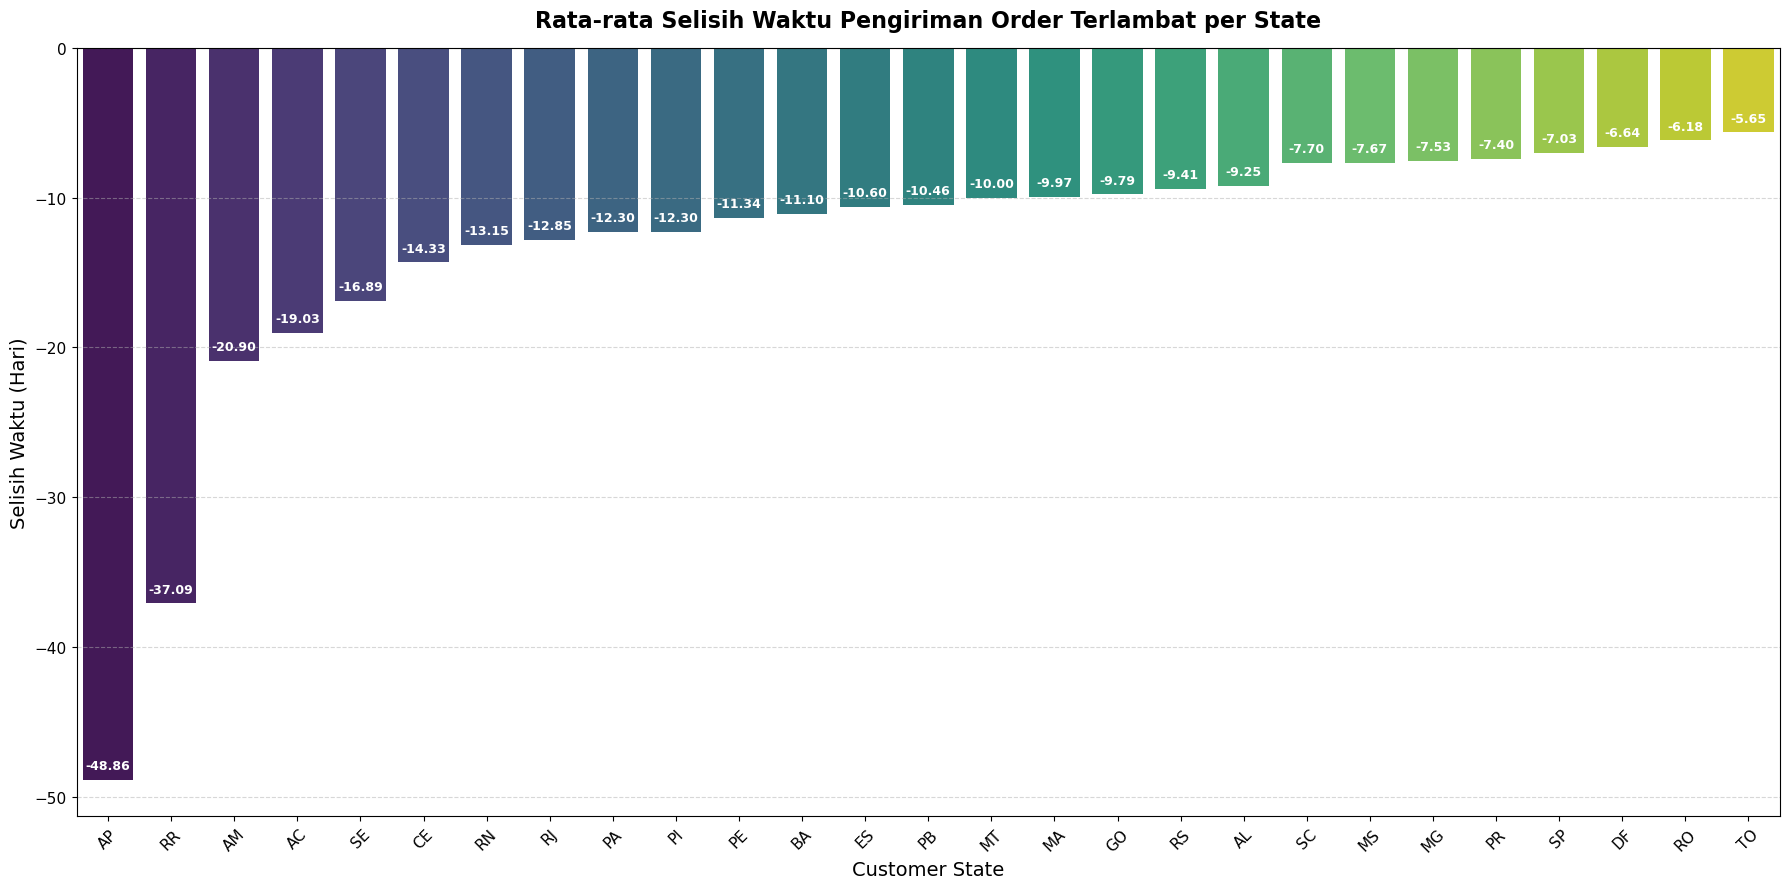

In [43]:
# Membuat vertical bar chart untuk membandingkan rata-rata selisih waktu pengiriman
# pada order yang terlambat berdasarkan state
plt.figure(figsize=(18, 9))

ax = sns.barplot(
    data=data_q3_clean,
    x='customer_state',
    y='avg_diff_days',
    hue='customer_state',
    palette='viridis',
    legend=False
)

# Menambahkan label selisih hari pada setiap batang
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='{:,.2f}',
        padding=-15,
        fontsize=9,
        color='white',
        fontweight='bold'
    )

# Menambahkan judul dan label sumbu
plt.title(
    'Rata-rata Selisih Waktu Pengiriman Order Terlambat per State',
    fontsize=16,
    fontweight='bold',
    pad=15
)
plt.xlabel('Customer State', fontsize=14)
plt.ylabel('Selisih Waktu (Hari)', fontsize=14)

# Memutar label state agar lebih mudah dibaca
plt.xticks(rotation=45, fontsize=11)
plt.yticks(fontsize=11)

# Menambahkan grid horizontal untuk memudahkan perbandingan
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### KEY INSIGHT 

Seluruh state menunjukkan rata-rata keterlambatan yang bernilai negatif, dengan AP memiliki selisih rata-rata terbesar yaitu -48,86 hari, diikuti RR sebesar -37,09 hari dan AM sebesar -20,90 hari. Namun, beberapa state memiliki jumlah order terlambat yang sangat sedikit, sehingga nilai rata-ratanya perlu diinterpretasikan dengan mempertimbangkan jumlah order yang dianalisis.

## KEY FINDINGS

1. Secara rata-rata, waktu pengiriman aktual di seluruh state lebih cepat dibandingkan estimasi yang diberikan kepada customer. Hal ini menunjukkan bahwa estimasi waktu pengiriman cenderung memberikan buffer waktu yang cukup, sehingga pengiriman aktual umumnya selesai sebelum tanggal estimasi.
2. Mayoritas order, yaitu **91,8876% (88.644 order)**, berhasil dikirim **tepat waktu sesuai estimasi**, sedangkan **8,1124% (7.826 order)** mengalami keterlambatan
3. Terdapat perbedaan selisih waktu pengiriman antar-state. AP memiliki selisih rata-rata terbesar sebesar -48,86 hari, diikuti RR (-37,09 hari) dan AM (-20,90 hari). Namun, hasil pada beberapa state perlu dipertimbangkan karena memiliki jumlah order yang relatif sedikit.

## BUSINESS IMPLICATIONS

1. **Evaluasi kembali estimasi waktu pengiriman**
   Karena waktu pengiriman aktual rata-rata lebih cepat dibandingkan estimasi, bisnis dapat mengevaluasi kembali buffer pada estimasi pengiriman agar informasi yang diberikan kepada customer lebih akurat.

2. **Fokus pada order yang mengalami keterlambatan**
   Meskipun mayoritas order berhasil dikirim tepat waktu, sekitar **8,11% order mengalami keterlambatan**. Order yang terlambat perlu dianalisis lebih lanjut untuk mengidentifikasi pola dan faktor yang berkaitan dengan keterlambatan.

3. **Prioritaskan evaluasi pada state dengan selisih waktu yang ekstrem**
   Perbedaan selisih waktu antar-state dapat menjadi dasar untuk melakukan evaluasi lebih lanjut terhadap proses pengiriman di masing-masing wilayah, terutama pada state dengan hasil ekstrem. State dengan jumlah order yang sedikit sebaiknya dievaluasi dengan lebih hati-hati agar tidak menghasilkan kesimpulan yang terlalu kuat dari observasi yang terbatas.


In [46]:
data_q1.to_excel('data_q1_clean.xlsx', index=False)
data_q2.to_excel('data_q2_clean.xlsx', index=False)
data_q3.to_excel('data_q3_clean.xlsx', index=False)